# Load Dataset

In [13]:
from pathlib import Path
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt

import tensorflow as tf
from sklearn.model_selection import train_test_split

Matplotlib is building the font cache; this may take a moment.


In [14]:
train_dir = "dataset/seg_train/seg_train"
test_dir = "dataset/seg_test/seg_test"

In [15]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


# Data Exploration

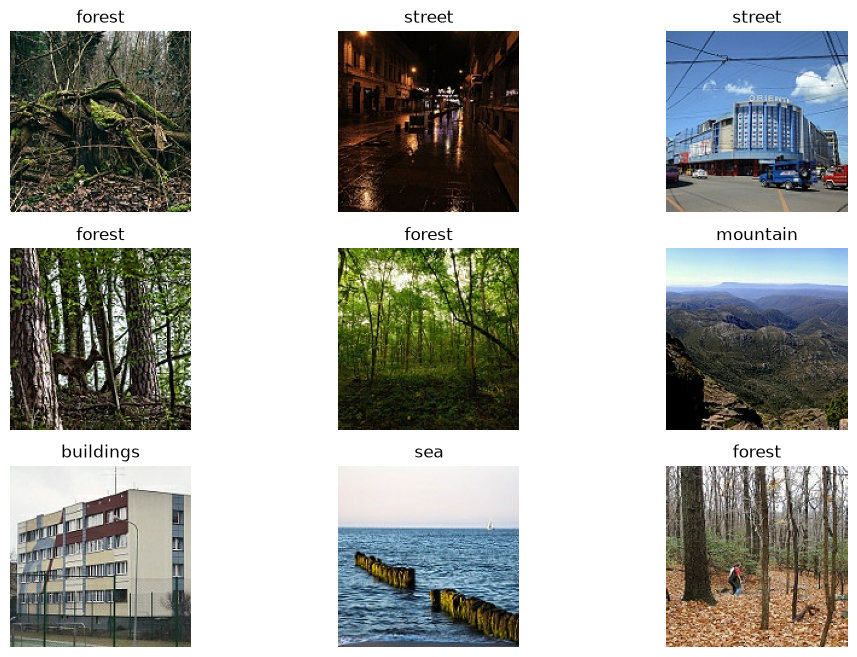

In [16]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

In [17]:
print(train_ds.element_spec)

(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [18]:
images, labels = next(iter(train_ds))

image = images[7]
print(image.shape)

label = labels[7]
print(label.numpy())

(150, 150, 3)
0


# Preprocess Data (for model from scratch)

In [19]:
AUTOTUNE = tf.data.AUTOTUNE

def normalize_images(images, labels):
    images = images / 255.0
    return images, labels

val_preprocessed = val_ds.map(normalize_images)
test_preprocessed = test_ds.map(normalize_images)

In [20]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

train_preprocessed = train_ds.map(
    lambda images, labels: (data_augmentation(images, training=True) / 255.0, labels)
)

In [21]:
train_preprocessed = train_preprocessed.prefetch(AUTOTUNE)
val_preprocessed = val_preprocessed.prefetch(AUTOTUNE)
test_preprocessed = test_preprocessed.prefetch(AUTOTUNE)

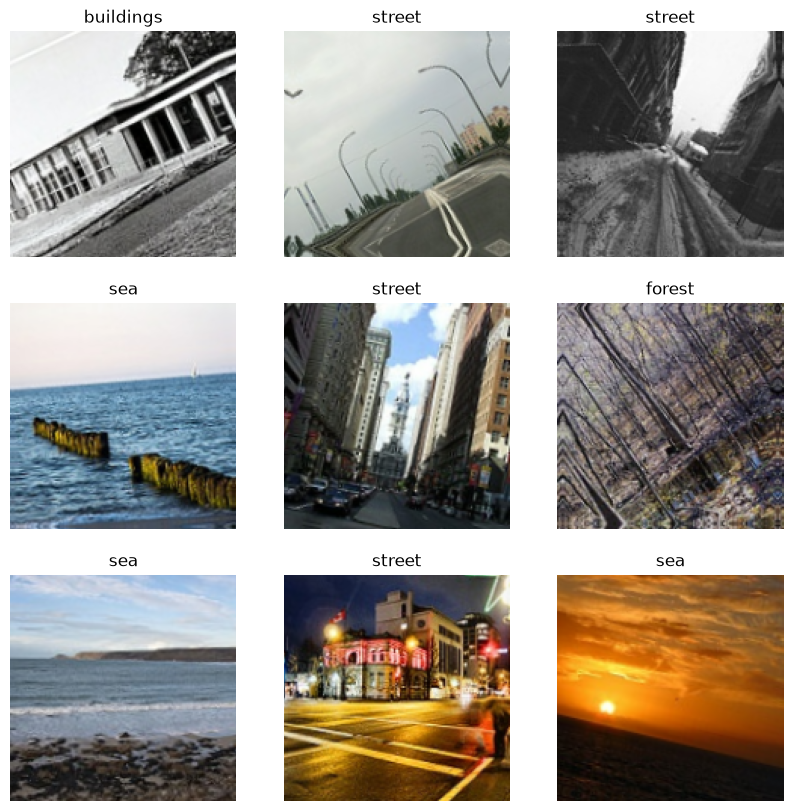

In [22]:
plt.figure(figsize=(10, 10))

for images, labels in train_preprocessed.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

# Pretrained Model

In [81]:
from keras.applications.vgg16 import VGG16, preprocess_input
from keras.layers import Dense, Flatten, Dropout
from keras import models,layers

In [82]:
def vgg_preprocessing(images, labels):
    images = preprocess_input(images)
    return images, labels


train_vgg = train_ds.map(vgg_preprocessing)
val_vgg = val_ds.map(vgg_preprocessing)
test_vgg = test_ds.map(vgg_preprocessing)

In [83]:
AUTOTUNE = tf.data.AUTOTUNE

train_vgg = train_vgg.prefetch(AUTOTUNE)
val_vgg = val_vgg.prefetch(AUTOTUNE)
test_vgg = test_vgg.prefetch(AUTOTUNE)

In [84]:
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))

In [85]:
vgg_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [86]:
for layer in vgg_base.layers:
    layer.trainable = False

In [87]:
x = vgg_base.output
x = Flatten()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)

output = Dense(6, activation="softmax")(x)

In [88]:
model = models.Model(
    inputs=vgg_base.input,
    outputs=output
)

In [89]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [90]:
history_1 = model.fit(
    train_vgg,
    epochs=5,
    validation_data=val_vgg,
    verbose=1
)

Epoch 1/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 663s 2s/step - accuracy: 0.8407 - loss: 1.6617 - val_accuracy: 0.8999 - val_loss: 0.4451
Epoch 2/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 572s 2s/step - accuracy: 0.8836 - loss: 0.4824 - val_accuracy: 0.8977 - val_loss: 0.3769
Epoch 3/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 1127s 3s/step - accuracy: 0.8974 - loss: 0.3888 - val_accuracy: 0.9045 - val_loss: 0.3991
Epoch 4/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 560s 2s/step - accuracy: 0.9053 - loss: 0.3743 - val_accuracy: 0.9145 - val_loss: 0.3903
Epoch 5/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 753s 2s/step - accuracy: 0.9157 - loss: 0.3204 - val_accuracy: 0.9170 - val_loss: 0.3808


### Fine-Tuning

In [92]:
for layer in vgg_base.layers[:-4]:
    layer.trainable = False
for layer in vgg_base.layers[-4:]:
    layer.trainable = True

In [93]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [94]:
history_2 = model.fit(
    train_vgg,
    epochs=5,
    validation_data=val_vgg,
    verbose=1
)

Epoch 1/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 653s 2s/step - accuracy: 0.9300 - loss: 0.2290 - val_accuracy: 0.9180 - val_loss: 0.3418
Epoch 2/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 672s 2s/step - accuracy: 0.9428 - loss: 0.1709 - val_accuracy: 0.9234 - val_loss: 0.3535
Epoch 3/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 1195s 3s/step - accuracy: 0.9517 - loss: 0.1373 - val_accuracy: 0.9269 - val_loss: 0.3628
Epoch 4/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 1674s 5s/step - accuracy: 0.9595 - loss: 0.1226 - val_accuracy: 0.9273 - val_loss: 0.3468
Epoch 5/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 640s 2s/step - accuracy: 0.9636 - loss: 0.1074 - val_accuracy: 0.9301 - val_loss: 0.3567


In [95]:
test_loss, test_acc = model.evaluate(test_vgg)
print(f"\n Test accuracy after fine-tuning: {test_acc:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.9207 - loss: 0.3398

 Test accuracy after fine-tuning: 0.9207


## Model From Scatch

In [39]:
import time, random
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, accuracy_score
import pandas as pd

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

NUM_CLASSES = len(class_names)
INPUT_SHAPE = IMG_SIZE + (3,)

In [36]:
L2 = regularizers.l2(1e-4)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def build_cnn():
    input = keras.Input(shape=INPUT_SHAPE)
    x = input

    for filters, drop in ((32, 0.1), (64, 0.2), (128, 0.3), (256, 0.4)):
        x = conv_block(x, filters)
        if filters > 32:
            x = conv_block(x, filters) # 2 convs per block -> more seperation between similar scenes -> less underfitting & higher f1
        x = layers.MaxPooling2D()(x) # shrinking keeping strongest features
        x = layers.Dropout(drop)(x)

    x = layers.GlobalAveragePooling2D()(x) # instead of flatten -> fewer parameters -> less memorizing -> less overfitting

    x = layers.Dense(128, activation='relu', kernel_regularizer=L2)(x) # L2 weight penalty -> less overfitting
    x = layers.Dropout(0.5)(x) # dropout in dense head -> less overfitting

    output = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return keras.Model(input, output, name="cnn_from_scratch")

model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), 
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
model.summary()
    

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_40 (Activation)      │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_41 (Activation)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 75, 75, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_42 (Activation)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_43 (Activation)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 37, 37, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_44 (Activation)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,199,462 (4.58 MB)

 Trainable params: 1,197,606 (4.57 MB)

 Non-trainable params: 1,856 (7.25 KB)

In [37]:
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint('best_cnn.keras', monitor='val_loss', save_best_only=True)
]

t0 = time.time()
history = model.fit(train_preprocessed, validation_data=val_preprocessed, epochs=10,
                    callbacks=callbacks, verbose=1)
print(f"training time: {(time.time() - t0)/60:.1f} min")

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 911s 3s/step - accuracy: 0.5387 - loss: 1.2457 - val_accuracy: 0.5413 - val_loss: 1.1454 - learning_rate: 0.0010
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 956s 3s/step - accuracy: 0.6670 - loss: 1.0029 - val_accuracy: 0.5969 - val_loss: 1.3208 - learning_rate: 0.0010
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 904s 3s/step - accuracy: 0.7126 - loss: 0.8910 - val_accuracy: 0.6333 - val_loss: 1.0586 - learning_rate: 0.0010
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 949s 3s/step - accuracy: 0.7431 - loss: 0.8198 - val_accuracy: 0.7316 - val_loss: 0.8758 - learning_rate: 0.0010
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 932s 3s/step - accuracy: 0.7586 - loss: 0.7797 - val_accuracy: 0.5930 - val_loss: 1.5851 - learning_rate: 0.0010
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 891s 3s/step - accuracy: 0.7674 - loss: 0.7577 - val_accuracy: 0.6404 - val_loss: 1.1830 - learning_rate: 0.0010
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7767 - loss: 0.73

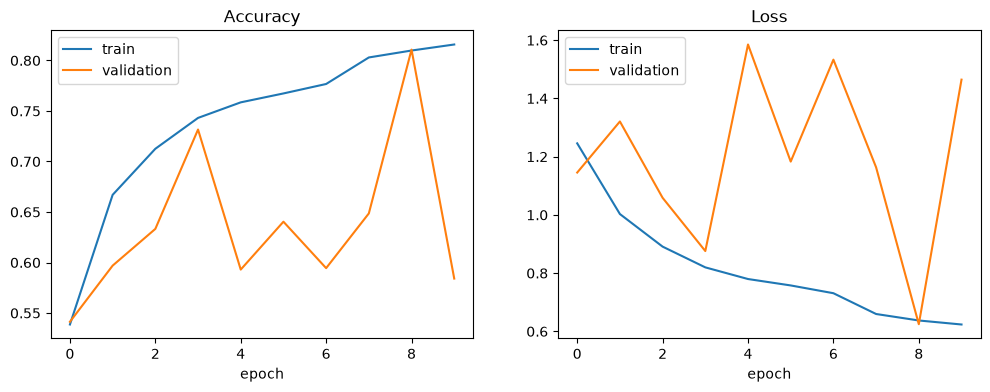

In [38]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()
# Overfitting  = train curve keeps improving, validation stalls or gets worse
# Underfitting = both curves stay low
# Good fit     = both converge close together at high accuracy

Test accuracy: 0.8020



,Precision,Recall,F1
Macro avg,0.8197,0.8083,0.8045
Weighted avg,0.8222,0.8020,0.8029


,Precision,Recall,F1,Support
buildings,0.6322,0.9245,0.7509,437
forest,0.9776,0.9219,0.9490,474
glacier,0.8530,0.6401,0.7314,553
mountain,0.7313,0.8190,0.7727,525
sea,0.8249,0.8314,0.8281,510
street,0.8992,0.7126,0.7951,501


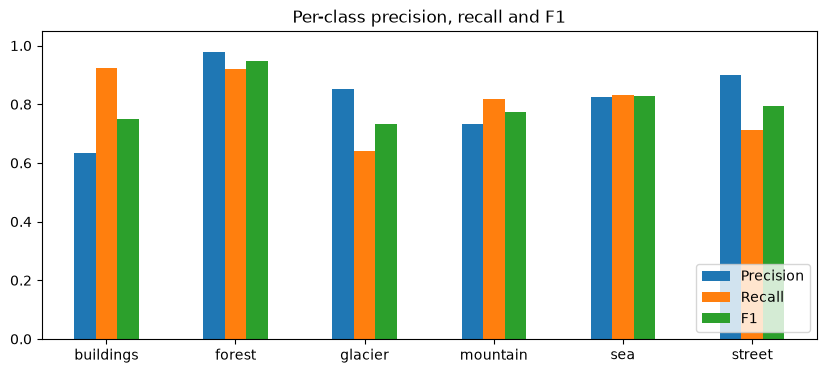

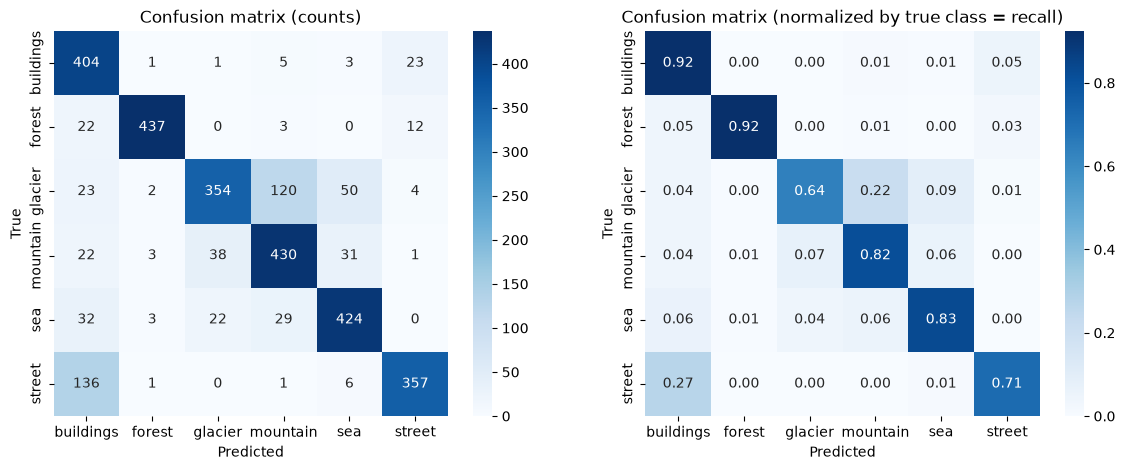

Top 5 confusions:


,True class,Predicted as,Count
22,street,buildings,136
10,glacier,mountain,120
11,glacier,sea,50
15,mountain,glacier,38
18,sea,buildings,32


In [ ]:
y_test = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = model.predict(test_preprocessed, verbose=0).argmax(axis=1)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
summary = pd.DataFrame({
    "Precision": [precision_score(y_test, y_pred, average=a) for a in ("macro", "weighted")],
    "Recall":    [recall_score(y_test, y_pred, average=a)    for a in ("macro", "weighted")],
    "F1":        [f1_score(y_test, y_pred, average=a)        for a in ("macro", "weighted")],
}, index=["Macro avg", "Weighted avg"])
display(summary.round(4))

per_class = pd.DataFrame({
    "Precision": precision_score(y_test, y_pred, average=None),
    "Recall":    recall_score(y_test, y_pred, average=None),
    "F1":        f1_score(y_test, y_pred, average=None),
    "Support":   np.bincount(y_test),
}, index=class_names)
display(per_class.round(4))

per_class[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4), ylim=(0, 1.05))
plt.title("Per-class precision, recall and F1"); plt.xticks(rotation=0); plt.legend(loc="lower right")
plt.show()

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Confusion matrix (normalized by true class = recall)")
for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.show()

errors = [(class_names[i], class_names[j], cm[i, j]) for i in range(NUM_CLASSES)
        for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]S
top_errors = pd.DataFrame(errors, columns=["True class", "Predicted as", "Count"]).sort_values("Count", ascending=False)
print("Top 5 confusions:")
display(top_errors.head(5))

model.save("cnn_from_scratch_final.keras")